In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

path = Path("data/processed/data_multinomial_classification.csv")
print("데이터 경로:", path)

if not path.is_file():
    project_root = Path.cwd().resolve()
    if project_root.name == "notebooks":
        project_root = project_root.parent

    candidates = [
        project_root / "data" / "processed" / "data_multinomial_classification.csv",
        project_root / "notebooks" / "data" / "processed" / "data_multinomial_classification.csv",
    ]

    for candidate in candidates:
        if candidate.is_file():
            path = candidate
            break
    else:
        raise FileNotFoundError(
            f"{path} 파일을 찾을 수 없습니다.\n검색 경로: {candidates}"
        )

data_frame = pd.read_csv(path, header=None)
print(f"전체 데이터 Shape: {data_frame.shape}")
print(data_frame.head())

데이터 경로: data/processed/data_multinomial_classification.csv
전체 데이터 Shape: (101, 17)
   0   1   2   3   4   5   6   7   8   9   10  11  12  13  14  15  16
0   1   0   0   1   0   0   1   1   1   1   0   0   4   0   0   1   0
1   1   0   0   1   0   0   0   1   1   1   0   0   4   1   0   1   0
2   0   0   1   0   0   1   1   1   1   0   0   1   0   1   0   0   3
3   1   0   0   1   0   0   1   1   1   1   0   0   4   0   0   1   0
4   1   0   0   1   0   0   1   1   1   1   0   0   4   1   0   1   0


In [2]:
x = data_frame.iloc[:, :-1].to_numpy()
y = data_frame.iloc[:, -1].to_numpy()

x = torch.tensor(x, dtype=torch.float32)
y = torch.tensor(y, dtype=torch.long)

print(f"x.shape: {x.shape}")
print(f"y.shape: {y.shape}")
print("x의 처음 5개 데이터:")
print(x[:5])
print("y의 처음 10개 Label:")
print(y[:10])

assert x.ndim == 2
assert y.ndim == 1

x.shape: torch.Size([101, 16])
y.shape: torch.Size([101])
x의 처음 5개 데이터:
tensor([[1., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 4., 0., 0., 1.],
        [1., 0., 0., 1., 0., 0., 0., 1., 1., 1., 0., 0., 4., 1., 0., 1.],
        [0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 1., 0., 1., 0., 0.],
        [1., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 4., 0., 0., 1.],
        [1., 0., 0., 1., 0., 0., 1., 1., 1., 1., 0., 0., 4., 1., 0., 1.]])
y의 처음 10개 Label:
tensor([0, 0, 3, 0, 0, 0, 0, 3, 3, 0])


In [3]:
classes = torch.unique(y)
num_classes = len(classes)

print("Classes :", classes.tolist())
print("Number of Classes :", num_classes)

Classes : [0, 1, 2, 3, 4, 5, 6]
Number of Classes : 7


## Q1.
---

CSV의 마지막 Column은 하나의 정답 값이지만, 인덱스이기도 합니다. 

즉, 마지막 Column이 0, 1, 2, 3처럼 여러 클래스 중 하나를 의미하므로 모델은 각 Class별 점수를 출력해야 합니다. 

따라서 Output Dimension은 반드시 Class 개수만큼 설정해야 합니다. 만약 Output Dimension을 1로 두면 여러 Class를 비교할 수 없게 됩니다.

---

In [4]:
num_inputs = x.shape[1]
num_classes = len(classes)

print("num_inputs =", num_inputs)
print("num_classes =", num_classes)

model = nn.Linear(num_inputs, num_classes)
print(model)

num_inputs = 16
num_classes = 7
Linear(in_features=16, out_features=7, bias=True)


In [5]:
logits = model(x)
print("logits의 처음 5개:")
print(logits[:5])
print("logits.shape:", logits.shape)

logits의 처음 5개:
tensor([[ 0.6730, -0.4776,  0.0923,  0.4707,  0.7977,  0.2443,  1.2023],
        [ 0.5976, -0.3839,  0.3287,  0.9018,  0.9900, -0.1714,  1.2196],
        [-0.4676,  0.1713,  0.3156, -0.4239,  0.0341, -0.3789,  0.5918],
        [ 0.6730, -0.4776,  0.0923,  0.4707,  0.7977,  0.2443,  1.2023],
        [ 0.5043, -0.3639,  0.2570,  0.7131,  0.8466,  0.0638,  1.4030]],
       grad_fn=<SliceBackward0>)
logits.shape: torch.Size([101, 7])


In [6]:
probability = F.softmax(logits, dim=1)

print("Logit:")
print(logits[:5])
print("\nSoftmax Probability:")
print(probability[:5])
print("\n각 데이터의 Probability 합:")
print(probability[:5].sum(dim=1))

Logit:
tensor([[ 0.6730, -0.4776,  0.0923,  0.4707,  0.7977,  0.2443,  1.2023],
        [ 0.5976, -0.3839,  0.3287,  0.9018,  0.9900, -0.1714,  1.2196],
        [-0.4676,  0.1713,  0.3156, -0.4239,  0.0341, -0.3789,  0.5918],
        [ 0.6730, -0.4776,  0.0923,  0.4707,  0.7977,  0.2443,  1.2023],
        [ 0.5043, -0.3639,  0.2570,  0.7131,  0.8466,  0.0638,  1.4030]],
       grad_fn=<SliceBackward0>)

Softmax Probability:
tensor([[0.1620, 0.0512, 0.0906, 0.1323, 0.1835, 0.1055, 0.2749],
        [0.1370, 0.0513, 0.1047, 0.1857, 0.2028, 0.0635, 0.2551],
        [0.0851, 0.1611, 0.1861, 0.0889, 0.1405, 0.0929, 0.2454],
        [0.1620, 0.0512, 0.0906, 0.1323, 0.1835, 0.1055, 0.2749],
        [0.1259, 0.0529, 0.0983, 0.1552, 0.1773, 0.0811, 0.3093]],
       grad_fn=<SliceBackward0>)

각 데이터의 Probability 합:
tensor([1.0000, 1.0000, 1.0000, 1.0000, 1.0000], grad_fn=<SumBackward1>)


In [7]:
prediction = torch.argmax(logits, dim=1)

for i in range(5):
    print(f"\nData Index {i}")
    print("Probability:", probability[i].tolist())
    print("Prediction:", prediction[i].item())
    print("Actual Label:", y[i].item())


Data Index 0
Probability: [0.1619592010974884, 0.0512484572827816, 0.09061550348997116, 0.13228610157966614, 0.18345415592193604, 0.10548916459083557, 0.2749474346637726]
Prediction: 6
Actual Label: 0

Data Index 1
Probability: [0.1369655281305313, 0.051327306777238846, 0.10466645658016205, 0.18565493822097778, 0.20278239250183105, 0.06347975134849548, 0.25512364506721497]
Prediction: 6
Actual Label: 0

Data Index 2
Probability: [0.08506070822477341, 0.16113808751106262, 0.18614687025547028, 0.08885960280895233, 0.14048102498054504, 0.09294509887695312, 0.2453685849905014]
Prediction: 6
Actual Label: 3

Data Index 3
Probability: [0.1619592010974884, 0.0512484572827816, 0.09061550348997116, 0.13228610157966614, 0.18345415592193604, 0.10548916459083557, 0.2749474346637726]
Prediction: 6
Actual Label: 0

Data Index 4
Probability: [0.12592479586601257, 0.0528520904481411, 0.09833576530218124, 0.15517647564411163, 0.17732803523540497, 0.08106375485658646, 0.30931907892227173]
Prediction: 6

## Q2.
---

Binary Classification은 하나의 Probability만 계산되어 `0.5`를 기준으로 두 Class 중 하나를 선택하면 되지만, 

Multinomial Classification은 여러 Class마다 logit을 계산하고 가장 큰 값을 가진 Class를 선택해야 하므로 `argmax()`를 사용합니다. 

---

In [8]:
torch.manual_seed(42)

model = nn.Linear(num_inputs, num_classes)
optimizer = torch.optim.SGD(model.parameters(), lr=0.1)

loss_history = []
accuracy_history = []

for epoch in range(2000):
    optimizer.zero_grad()
    logits = model(x)
    loss = F.cross_entropy(logits, y)
    loss.backward()
    optimizer.step()

    with torch.no_grad():
        logits = model(x)
        prediction = torch.argmax(logits, dim=1)
        accuracy = (prediction == y).float().mean().item()
        loss_history.append(loss.item())
        accuracy_history.append(accuracy)

print("학습 완료")
print("최종 Loss:", loss_history[-1])
print("최종 Accuracy:", accuracy_history[-1])
if accuracy_history[-1] >= 0.95:
    print("Accuracy 조건 만족: 95% 이상")
else:
    print("Accuracy 조건 미만: 학습 조건을 다시 확인하세요.")

학습 완료
최종 Loss: 0.05571763962507248
최종 Accuracy: 1.0
Accuracy 조건 만족: 95% 이상


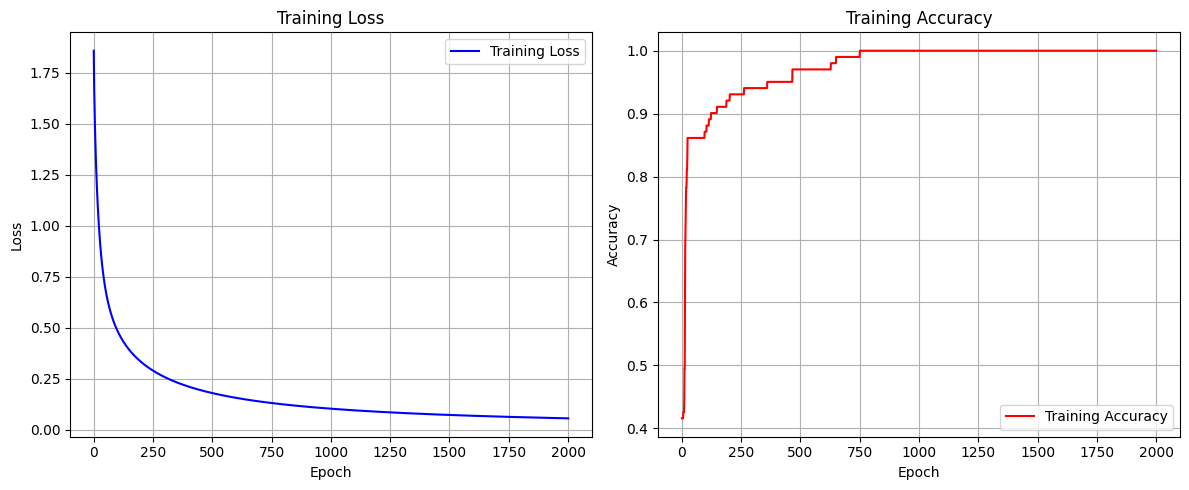

In [9]:
epochs = list(range(1, len(loss_history) + 1))

plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.plot(epochs, loss_history, color="blue", label="Training Loss")
plt.title("Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs, accuracy_history, color="red", label="Training Accuracy")
plt.title("Training Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()

## Q3.
---

Loss 그래프는 학습이 진행될수록 값이 감소하고, Accuracy 그래프는 점점 증가합니다. 

이는 모델이 데이터를 학습하면서 더 좋은 분류 경계를 찾고 있음을 의미합니다. 

최종적으로 Accuracy가 95% 이상에 도달하면 모델이 실제로 학습되었다고 판단할 수 있습니다.

---

In [10]:
with torch.no_grad():
    final_logits = model(x)
    final_probability = F.softmax(final_logits, dim=1)
    final_prediction = torch.argmax(final_logits, dim=1)

print("Prediction\tActual Label\tClass Probability")
for i in range(10):
    prob = final_probability[i]
    pred = final_prediction[i].item()
    label = y[i].item()
    class_prob = prob[pred].item()
    print(f"{pred:>10} \t{label:>11} \t{class_prob:.4f}")

misclassified_index = torch.nonzero(final_prediction != y, as_tuple=False).flatten()
print(f"\n오분류 개수: {len(misclassified_index)}")

if len(misclassified_index) > 0:
    print("\n최대 3개의 오분류 데이터:")
    for idx in misclassified_index[:3]:
        idx = idx.item()
        p = final_probability[idx]
        pred = final_prediction[idx].item()
        label = y[idx].item()
        print(f"Data Index: {idx}")
        print(f"Prediction: {pred}")
        print(f"Actual Label: {label}")
        print(f"Class Probability: {p.tolist()}")
        print("-" * 50)
else:
    print("오분류된 데이터가 없습니다. Accuracy가 100%인 상태입니다.")

Prediction	Actual Label	Class Probability
         0 	          0 	0.9972
         0 	          0 	0.9974
         3 	          3 	0.9700
         0 	          0 	0.9972
         0 	          0 	0.9962
         0 	          0 	0.9974
         0 	          0 	0.9982
         3 	          3 	0.9851
         3 	          3 	0.9700
         0 	          0 	0.9906

오분류 개수: 0
오분류된 데이터가 없습니다. Accuracy가 100%인 상태입니다.


## Q4.
---

오분류가 발생한 경우, 해당 샘플의 Probability 분포를 보면 두 Class의 값이 비슷하게 큰 경우가 많습니다. 

즉, 모델이 어떤 두 Class 사이에서 혼동하고 있는지를 확인할 수 있습니다. 오분류가 없다면 Accuracy가 100%가 되었음을 확인하고 넘어갑니다.

---

## Q5.
---

Logistic Regression은 하나의 출력만을 생성하여 확률값을 나타내고, 이 확률이 0.5를 넘는지 여부로 Class 0/1을 결정합니다. 

반면 Multinomial Classification은 Class 개수만큼 여러 개의 logit을 출력하고, 각 Class의 점수를 비교한 뒤 `argmax()`를 사용해 가장 높은 Class를 선택합니다. 

다시말해 Output의 형태와 Class 결정 방식이 가장 큰 차이입니다.

---

In [11]:
print(f"Class 개수 : {num_classes}")
print(f"사용한 Epoch : {len(loss_history)}")
print("사용한 Learning Rate : 0.1")
print(f"최종 Loss : {loss_history[-1]:.4f}")
print(f"최종 Accuracy : {accuracy_history[-1] * 100:.2f}%")

Class 개수 : 7
사용한 Epoch : 2000
사용한 Learning Rate : 0.1
최종 Loss : 0.0557
최종 Accuracy : 100.00%
